# Homework 6: Linear Regression Modleing and Diagnostics
Build a predictive model for life expectancy using scikit-learn and perform a diagnostic audit to ensure the model’s coefficients are stable and mathematically sound.

## Task 1: Baseline Modeling
Load the WHO Life Expectancy Dataset, remove non-numeric columns (Country, Year), Convert Status column to  numeric, handle missing values.
- Use StandardScaler from sklearn.preprocessing to scale all independent variables. ('Life expectancy' is dependent variable) 
- Train a LinearRegression model using the scaled features.
- Report the R-Squared Score.
- Coefficient Analysis: Rank the features by their absolute coefficient values. Because the data is scaled, the largest coefficient now represents the most important predictor.

## Task 2: Iterative Diagnostic (VIF < 5)
Before analyzing the data, you must understand the Variance Inflation Factor (VIF) diagnostic. VIF measures multicollinearity, the degree to which your predictors are redundant.
High multicollinearity inflates the variance of coefficients, making them unreliable and difficult to interpret.
VIF is calculated by regressing one predictor against all others, then you obtain R_Squared and then compute VIF = 1/(1-R_Squared)
You sohuld use a cutoff of 5. Any variable with a VIF > 5 is considered too redundant and will be removed to improve the model's structural integrity. To do that follow the instruction below:

### Write a loop to iteratively remove the most redundant feature:
    1. Calculate VIF for every feature in the scaled dataset.
    2. Find the variable with the highest VIF.
    3. If VIF > 5, remove that feature from the data.
    4. Repeats the process until all remaining features have a VIF < 5
    - Note that in each iteration you remove only the highest VIF if it is greatet than 5!
    
## Task 3: Comparison of Model Results
    - Train a new LinearRegression model using only the independent features that survived the VIF diagnostic test.
    - Report the R-Squared Score.
    - Coefficient Analysis: Rank the features by their absolute coefficient values. Because the data is scaled, the largest coefficient now represents the most important predictor.
    - Are the top 5 predicotrs remain the same as those of the Baseline Model?

## Task 4: Residual Analysis and Normality
A good regression model should have errors (residuals) that are normally distributed and centered around zero.

    - Generate a histogram of the residuals for your baseline and clean model side by side.
    - Does the error distributions look like a bell curve?

## Task 5: The Interaction Investigation
In the real world application, the effect of one variable often depends on another. This is called an interaction.

    - Select two variables of your choice from the dataset (only variables with VIF >5) that you believe might have a combined effect (e.g., Alcohol and GDP, or BMI and HIV/AIDS,). Write one sentence explaining why you think they interact.
    - Create a new column in your dataframe by multiplying these two variables together.
    - Train a new model by adding this new interaction term to your dataset and fit it again using LinearRegression.
    - Report the R-Squared Score.
    - Is the interaction coeficient positive or negative? Has adding it improved the Model performance?




# Task 1

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [41]:
# Load the dataset
df = pd.read_csv('C:/Users/ryanj/Downloads/101 DATA/Life_Expectancy_Data.csv')

# Clean column names
df.columns = df.columns.str.strip()

# Dropping NA values
df = df.dropna()

# Convert Status column to numeric
df['Status_Encoded'] = df['Status'].map({'Developed': 1, 'Developing': 0})

df_numeric = df.select_dtypes(include = [np.number])
X = df_numeric.drop('Life expectancy', axis = 1)
y = df_numeric['Life expectancy']

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns = X.columns)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size = 0.2, random_state = 42)

baseline_model = LinearRegression().fit(X_train, y_train)
baseline_preds = baseline_model.predict(X_test)
baseline_r2 = r2_score(y_test, baseline_preds)

print(f'Baseline Model Results')
print(f'Baseline Test R-Squared Score: {baseline_r2:.2f}')

baseline_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': baseline_model.coef_,
    'Abs_Coefficient': np.abs(baseline_model.coef_)
}).sort_values(by='Abs_Coefficient', ascending = False)

print('Baseline Feature Weights (Ranked by Absolute Value):')
print(baseline_importance[['Feature', 'Coefficient']])

Baseline Model Results
Baseline Test R-Squared Score: 0.82
Baseline Feature Weights (Ranked by Absolute Value):
                            Feature  Coefficient
8                 under-five deaths   -11.300936
2                     infant deaths    11.128412
18                        Schooling     2.700707
12                         HIV/AIDS    -2.655394
1                   Adult Mortality    -2.030575
17  Income composition of resources     1.735946
3                           Alcohol    -0.603981
4            percentage expenditure     0.603237
7                               BMI     0.516978
0                              Year    -0.462927
19                   Status_Encoded     0.329680
11                       Diphtheria     0.307272
10                Total expenditure     0.243821
16               thinness 5-9 years    -0.218191
15             thinness  1-19 years    -0.183879
9                             Polio     0.177901
5                       Hepatitis B    -0.153186
13    

# Task 2

In [36]:
X_vif = X_scaled.copy()

while True:
    vif_data = pd.DataFrame()
    vif_data['Feature'] = X_vif.columns
    vif_data['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
    
    # Finding the highest VIF
    max_vif = vif_data['VIF'].max()
    max_vif_feature = vif_data.loc[vif_data['VIF'] == max_vif, 'Feature'].values[0]
    
    if max_vif > 5:
        print(f'{max_vif_feature} has a VIF of {max_vif:.2f}')
        X_vif = X_vif.drop(columns = [max_vif_feature])
    else:
        break

print(f'\nRemaining features with VIF < 5: {list(X_vif.columns)}')

infant deaths has a VIF of 213.61
GDP has a VIF of 13.71
thinness  1-19 years has a VIF of 7.61

Remaining features with VIF < 5: ['Year', 'Adult Mortality', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'Population', 'thinness 5-9 years', 'Income composition of resources', 'Schooling', 'Status_Encoded']


# Task 3

In [37]:
X_train_vif, X_test_vif, y_train_vif, y_test_vif = train_test_split(X_vif, y, test_size = 0.2, random_state = 42)

clean_model = LinearRegression().fit(X_train_vif, y_train_vif)
clean_preds = clean_model.predict(X_test_vif)
clean_r2 = r2_score(y_test_vif, clean_preds)

print(f'Clean Model Results')
print(f'Clean Model Test R-Squared Score: {clean_r2:.2f}')

clean_importance = pd.DataFrame({
    'Feature': X_vif.columns,
    'Coefficient': clean_model.coef_,
    'Abs_Coefficient': np.abs(clean_model.coef_)
}).sort_values(by = 'Abs_Coefficient', ascending = False)

print('Clean Model Feature Weights:')
print(clean_importance[['Feature', 'Coefficient']])

top_5_baseline = baseline_importance['Feature'].head(5).tolist()
top_5_clean = clean_importance['Feature'].head(min(5, len(clean_importance))).tolist()
print(f'\nTop 5 Baseline Predictors: {top_5_baseline}')
print(f'Top 5 Clean Model Predictors: {top_5_clean}')

Clean Model Results
Clean Model Test R-Squared Score: 0.81
Clean Model Feature Weights:
                            Feature  Coefficient
15                        Schooling     2.803633
11                         HIV/AIDS    -2.678511
1                   Adult Mortality    -2.131606
14  Income composition of resources     1.858635
2                           Alcohol    -0.831126
3            percentage expenditure     0.722078
6                               BMI     0.569260
0                              Year    -0.534983
10                       Diphtheria     0.439611
7                 under-five deaths    -0.381222
16                   Status_Encoded     0.338775
13               thinness 5-9 years    -0.261042
9                 Total expenditure     0.222099
8                             Polio     0.199597
4                       Hepatitis B    -0.169288
12                       Population     0.168716
5                           Measles     0.086433

Top 5 Baseline Predictors: ['

# Task 4

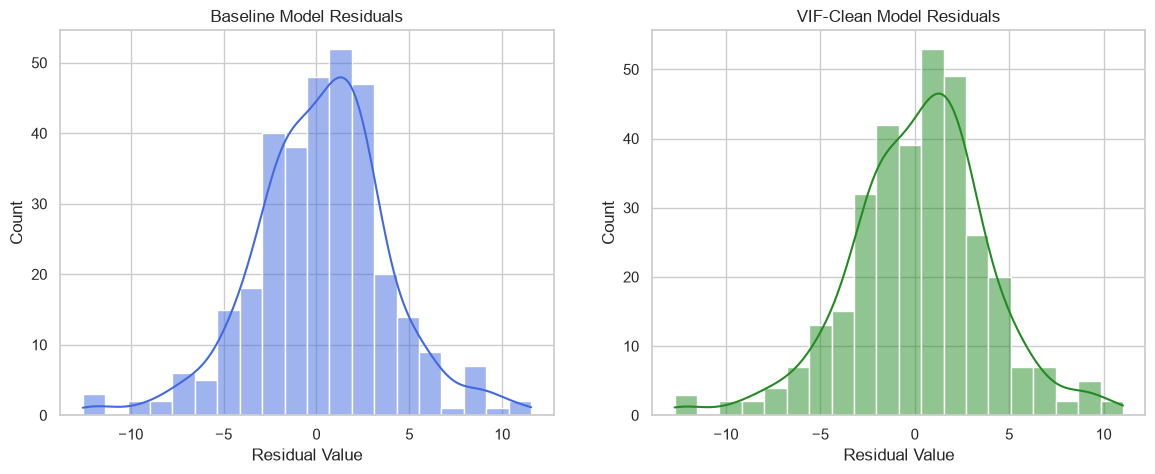

In [38]:
baseline_residuals = y_test - baseline_preds
clean_residuals = y_test_vif - clean_preds

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 5))

sns.histplot(baseline_residuals, kde = True, ax = ax1, color = 'royalblue')
ax1.set_title('Baseline Model Residuals')
ax1.set_xlabel('Residual Value')
ax1.set_ylabel('Count')

sns.histplot(clean_residuals, kde = True, ax = ax2, color = 'forestgreen')
ax2.set_title('VIF-Clean Model Residuals')
ax2.set_xlabel('Residual Value')
ax2.set_ylabel('Count')

plt.show()

# Task 5

In [40]:
# GDP and percentage expenditure interact because when a country has more money overall
# its health spending works even better to help people live longer

# Create interaction column
df['GDP_Exp_Inter'] = df['GDP'] * df['percentage expenditure']

# Combine interaction with clean VIF features
X_inter = X_vif.copy()
X_inter['GDP_Exp_Inter'] = df['GDP_Exp_Inter']

# Standardize the updated feature set
X_inter_scaled = pd.DataFrame(scaler.fit_transform(X_inter), columns=X_inter.columns)

# Train model with interaction 
X_train_int, X_test_int, y_train_int, y_test_int = train_test_split(X_inter_scaled, y, test_size = 0.2, random_state = 42)
inter_model = LinearRegression().fit(X_train_int, y_train_int)
inter_preds = inter_model.predict(X_test_int)
inter_r2 = r2_score(y_test_int, inter_preds)

print(f'Interaction Model Test R-Squared Score: {inter_r2:.2f}')

inter_coef = inter_model.coef_[list(X_inter_scaled.columns).index('GDP_Exp_Inter')]
print(f'Interaction Coefficient: {inter_coef:.2f}')
print(f'Is interaction coefficient positive? {inter_coef > 0}')
print(f'Does adding it improve the Model performance? {inter_r2 > clean_r2}')

Interaction Model Test R-Squared Score: 0.81
Interaction Coefficient: -0.55
Is interaction coefficient positive? False
Does adding it improve the Model performance? True
